# Part 1 — Data cleaning and weather enrichment
**CareClick Clinics · No-show prediction capstone**

**Goal:** turn the messy booking export `data/Appointments.csv` into one clean, analysis-ready table with exactly **16 columns**, enriched with daily temperature for each clinic from the free **Open-Meteo** API.

**Steps**
1. Load and profile the raw file
2. Clean: duplicates, column names, dates, categories, yes/no flags, age
3. Build features: `lead_days` and `lead_quartile` (quartiles/medians are computed on **all rows**, before any train/test split)
4. Enrich each clinic with temperature (Open-Meteo)
5. Validate and export `data/Appointments_clean.csv`

> All data in this repo is **synthetic** (generated by `src/generate_synthetic_data.py`, seed 42).

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

DATA = Path("../data")
OUT = Path("../outputs")
(OUT / "figures").mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

cleaning_log = []

## 1. Load and profile the raw file
Everything is read as text first so nothing is silently converted (e.g. `Y`/`N`, `01/06/2026`).

In [2]:
raw = pd.read_csv(DATA / "Appointments.csv", dtype=str, keep_default_na=False)
print("raw shape:", raw.shape)
raw.head(8)

raw shape: (12180, 13)


,AppointmentID,PatientId,Gender,Age,ScheduledDay,AppointmentDay,Clinic,City,Specialty,SMS_received,Insured,PreviousNoShows,No-show
0,1004768,700475,M,45.0,2026-08-18,2026-08-19,adyar clinic,CHENNAI,DENTAL,No,N,3,1
1,1008969,705653,female,36.0,25 May 2026,01/06/2026,CC-Saket,Delhi,Gen Medicine,1,No,0,0
2,1001140,705076,M,29.0,29 Sep 2026,29 Sep 2026,whitefield clinic,BENGALURU,ORTHOPEDICS,0,No,0,No
3,1002373,704174,m,9.0,17/07/2026,2026-07-27,careclick andheri,MUMBAI,ORTHOPEDICS,1,0,2,0
4,1007900,701395,,68.0,20/07/2026,22/07/2026,TNagar Clinic,Madras,Pediatrics,Yes,N,0,N
5,1002272,705533,FEMALE,42.0,21/07/2026,24 Jul 2026,TNagar Clinic,Chennai,Derma,N,N,0,No
6,1004990,704123,f,55.0,2026-08-30,2026-09-22,careclick indiranagar,Bangalore,paediatrics,N,N,2,No
7,1008317,704540,m,19.0,2026-06-15,26/06/2026,CARECLICK BANDRA,MUMBAI,Gen Medicine,0,Yes,0,N


In [3]:
profile = pd.DataFrame({"unique_values": raw.nunique(), "blank_cells": (raw == "").sum()})
print("exact duplicate rows:", raw.duplicated().sum())
profile

exact duplicate rows: 180


,unique_values,blank_cells
AppointmentID,12000,0
PatientId,5168,0
Gender,11,121
Age,93,149
ScheduledDay,897,0
AppointmentDay,698,0
Clinic,32,0
City,17,357
Specialty,24,0
SMS_received,6,0


**What the profile tells us**
- exact duplicate rows exist
- `Gender`, `Clinic`, `City`, `Specialty` and the yes/no columns have many spellings of the same value
- dates come in three formats; ages can be blank or impossible
- some bookings may have an appointment date *before* the booking date

## 2. Clean the data

In [4]:
df = raw.rename(columns={
    "AppointmentID": "appointment_id", "PatientId": "patient_id", "Gender": "gender", "Age": "age",
    "ScheduledDay": "scheduled_date", "AppointmentDay": "appointment_date", "Clinic": "clinic_raw",
    "City": "city_raw", "Specialty": "specialty_raw", "SMS_received": "sms_received",
    "Insured": "insurance_covered", "PreviousNoShows": "previous_no_shows", "No-show": "no_show",
}).copy()

n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
assert df["appointment_id"].is_unique, "appointment_id should be unique after de-duplication"
cleaning_log.append(("Drop exact duplicate rows", n0, len(df), "same booking exported twice"))
print(f"duplicates removed: {n0 - len(df)}")

duplicates removed: 180


In [5]:
def parse_date(s: pd.Series) -> pd.Series:
    s = s.str.strip()
    out = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    for fmt in ("%d/%m/%Y", "%d %b %Y"):
        out = out.fillna(pd.to_datetime(s, format=fmt, errors="coerce"))
    return out

df["scheduled_date"] = parse_date(df["scheduled_date"])
df["appointment_date"] = parse_date(df["appointment_date"])
assert df[["scheduled_date", "appointment_date"]].notna().all().all(), "unparsed dates remain"
print(df[["scheduled_date", "appointment_date"]].agg(["min", "max"]))

    scheduled_date appointment_date
min     2025-11-19       2025-12-25
max     2026-09-30       2026-09-30


In [6]:
df["gender"] = (df["gender"].str.strip().str.lower()
                .map({"m": "M", "male": "M", "f": "F", "female": "F"}).fillna("Unknown"))

spec_map = {"general medicine": "General Medicine", "gen medicine": "General Medicine",
            "pediatrics": "Pediatrics", "paediatrics": "Pediatrics",
            "dermatology": "Dermatology", "derma": "Dermatology",
            "cardiology": "Cardiology", "cardio": "Cardiology",
            "orthopedics": "Orthopedics", "orthopaedics": "Orthopedics", "ortho": "Orthopedics",
            "dental": "Dental", "dentistry": "Dental"}
df["specialty"] = df["specialty_raw"].str.strip().str.lower().map(spec_map)
assert df["specialty"].notna().all(), "unmapped specialty"

YES, NO = {"yes", "y", "1"}, {"no", "n", "0"}
def to_binary(s: pd.Series) -> pd.Series:
    s = s.str.strip().str.lower()
    out = pd.Series(np.nan, index=s.index)
    out[s.isin(YES)] = 1
    out[s.isin(NO)] = 0
    assert out.notna().all(), f"unrecognised flag values in {s.name}"
    return out.astype(int)

for col in ["sms_received", "insurance_covered", "no_show"]:
    df[col] = to_binary(df[col])
df["previous_no_shows"] = pd.to_numeric(df["previous_no_shows"]).astype(int)
print(df[["gender", "specialty", "sms_received", "insurance_covered", "no_show"]].describe(include="all").loc[["count", "unique", "top"]])

       gender         specialty  sms_received  insurance_covered  no_show
count   12000             12000       12000.0            12000.0  12000.0
unique      3                 6           NaN                NaN      NaN
top         F  General Medicine           NaN                NaN      NaN


In [7]:
clinics = pd.read_csv(DATA / "clinics.csv")
squash = lambda t: re.sub(r"[^a-z]", "", t.lower())
keys = {squash(n.replace("CareClick", "")): n for n in clinics["clinic_name"]}

def canonical_clinic(raw_name: str):
    key = squash(raw_name)
    for short, full in keys.items():
        if short in key:
            return full
    return np.nan

df["clinic"] = df["clinic_raw"].map(canonical_clinic)
assert df["clinic"].notna().all(), "unmapped clinic name"
df = df.merge(clinics.rename(columns={"clinic_name": "clinic"}), on="clinic", how="left")

alias = {"bangalore": "bengaluru", "bombay": "mumbai", "new delhi": "delhi", "madras": "chennai"}
raw_city = df["city_raw"].str.strip().str.lower().replace(alias)
known = raw_city != ""
print("raw city disagrees with clinic master:", int((raw_city[known] != df.loc[known, "city"].str.lower()).sum()),
      "| blank raw cities filled from master:", int((~known).sum()))
print(df["clinic"].value_counts())

raw city disagrees with clinic master: 0 | blank raw cities filled from master: 349
clinic
CareClick Indiranagar    1852
CareClick Andheri        1598
CareClick Saket          1559
CareClick T Nagar        1476
CareClick Adyar          1451
CareClick Bandra         1410
CareClick Dwarka         1371
CareClick Whitefield     1283
Name: count, dtype: int64


In [8]:
df["age"] = pd.to_numeric(df["age"], errors="coerce")
invalid_age = df["age"].isna() | (df["age"] < 0) | (df["age"] > 110)
df.loc[invalid_age, "age"] = np.nan
age_median = df["age"].median()
df["age"] = df["age"].fillna(age_median).round().astype(int)
cleaning_log.append(("Fix invalid / missing age", len(df), len(df), f"{int(invalid_age.sum())} values set to median age {age_median:.0f}"))
print(f"invalid ages fixed: {int(invalid_age.sum())}  (median = {age_median:.0f})")

invalid ages fixed: 201  (median = 37)


## 3. Feature engineering: lead time
`lead_days` = days between booking and appointment. A booking whose appointment is *before* its booking date is impossible, so those rows are dropped.
`lead_quartile` (1 = shortest wait … 4 = longest wait) uses cut-offs computed on **all rows** — as the project rules require.

In [9]:
df["lead_days"] = (df["appointment_date"] - df["scheduled_date"]).dt.days
n0 = len(df)
df = df[df["lead_days"] >= 0].reset_index(drop=True)
cleaning_log.append(("Drop appointment before booking date", n0, len(df), "impossible date order"))
print(f"rows with appointment before booking removed: {n0 - len(df)}")

q1, q2, q3 = df["lead_days"].quantile([0.25, 0.50, 0.75])
print(f"lead_days quartile cut-offs on all {len(df):,} rows: Q1={q1}, median={q2}, Q3={q3}")
assert q1 < q2 < q3, "quartile cut-offs must be distinct"
df["lead_quartile"] = np.digitize(df["lead_days"], [q1, q2, q3], right=True) + 1
df.groupby("lead_quartile")["lead_days"].agg(["count", "min", "max", "mean"]).round(1)

rows with appointment before booking removed: 36
lead_days quartile cut-offs on all 11,964 rows: Q1=3.0, median=7.0, Q3=13.0


,count,min,max,mean
lead_quartile,,,,
1,3774,0,3,1.1
2,2749,4,7,5.4
3,2739,8,13,10.2
4,2702,14,60,21.4


## 4. Enrich clinics with temperature (Open-Meteo)
For each of the 8 clinics we request **daily mean temperature** at the clinic's coordinates for the whole appointment period from the free [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) (no API key needed) and join it to each appointment by `(clinic, appointment_date)`.

If the API cannot be reached (offline, firewall, rate limit), the notebook falls back to a **clearly labelled synthetic seasonal temperature** so the pipeline still runs. The source is printed and stored in `data/clinic_weather.csv`.

In [10]:
API_URL = "https://archive-api.open-meteo.com/v1/archive"
start, end = df["appointment_date"].min().date(), df["appointment_date"].max().date()

def fetch_open_meteo(lat, lon):
    r = requests.get(API_URL, timeout=30, params={
        "latitude": lat, "longitude": lon, "start_date": str(start), "end_date": str(end),
        "daily": "temperature_2m_mean", "timezone": "Asia/Kolkata"})
    r.raise_for_status()
    d = r.json()["daily"]
    return pd.DataFrame({"date": pd.to_datetime(d["time"]), "temp_mean_c": d["temperature_2m_mean"]})

CLIMATE = {"Bengaluru": (24.5, 2.5, 110), "Mumbai": (28.0, 2.5, 130), "Delhi": (25.0, 10.0, 170), "Chennai": (29.0, 3.0, 150)}

def synthetic_temps(city, seed):
    mean, amp, peak = CLIMATE[city]
    days = pd.date_range(start, end)
    rng = np.random.default_rng(seed)
    t = mean + amp * np.sin(2 * np.pi * (days.dayofyear - peak + 91.25) / 365) + rng.normal(0, 1.0, len(days))
    return pd.DataFrame({"date": days, "temp_mean_c": t.round(1)})

frames, sources = [], {}
for _, c in clinics.iterrows():
    try:
        w, src = fetch_open_meteo(c["latitude"], c["longitude"]), "open-meteo"
    except Exception as e:
        w, src = synthetic_temps(c["city"], SEED + int(c["clinic_id"][2:])), "synthetic_fallback"
        sources[c["clinic_id"]] = f"{type(e).__name__}"
    w["clinic_id"], w["source"] = c["clinic_id"], src
    frames.append(w)

weather = pd.concat(frames, ignore_index=True)[["clinic_id", "date", "temp_mean_c", "source"]]
weather.to_csv(DATA / "clinic_weather.csv", index=False)
print("TEMPERATURE SOURCE PER CLINIC:", weather.groupby("clinic_id")["source"].first().to_dict())
if sources:
    print("Open-Meteo was not reachable from this environment -> synthetic seasonal fallback used. "
          "Re-run this notebook on a machine with internet access to pull real values.")
weather.groupby("clinic_id")["temp_mean_c"].describe().round(1)

TEMPERATURE SOURCE PER CLINIC: {'CC01': 'open-meteo', 'CC02': 'open-meteo', 'CC03': 'open-meteo', 'CC04': 'open-meteo', 'CC05': 'open-meteo', 'CC06': 'open-meteo', 'CC07': 'open-meteo', 'CC08': 'open-meteo'}


,count,mean,std,min,25%,50%,75%,max
clinic_id,,,,,,,,
CC01,269.0,24.6,2.4,18.8,23.3,24.4,26.0,29.9
CC02,269.0,24.6,2.4,18.7,23.6,24.7,26.0,29.5
CC03,269.0,28.1,2.1,22.6,26.8,27.7,29.9,32.1
CC04,269.0,28.1,2.1,22.6,26.8,27.7,29.9,32.1
CC05,269.0,26.9,6.7,9.8,23.4,28.8,31.3,37.4
CC06,269.0,26.8,6.6,10.2,23.7,28.4,31.1,37.6
CC07,269.0,29.5,2.6,23.2,27.9,30.1,31.3,34.3
CC08,269.0,29.5,2.6,23.2,27.9,30.0,31.3,34.3


In [11]:
df = df.merge(weather[["clinic_id", "date", "temp_mean_c"]],
              left_on=["clinic_id", "appointment_date"], right_on=["clinic_id", "date"], how="left")
missing_temp = int(df["temp_mean_c"].isna().sum())
clinic_median = df.groupby("clinic_id")["temp_mean_c"].transform("median")
df["avg_temp_c"] = df["temp_mean_c"].fillna(clinic_median).round(1)
print(f"appointments with no temperature for their day: {missing_temp} (filled with the clinic median)")

appointments with no temperature for their day: 0 (filled with the clinic median)


## 5. Validate and export the clean 16-column table

In [12]:
FINAL_COLS = ["appointment_id", "patient_id", "gender", "age", "scheduled_date", "appointment_date",
              "lead_days", "lead_quartile", "clinic", "city", "specialty", "sms_received",
              "insurance_covered", "previous_no_shows", "avg_temp_c", "no_show"]
clean = df[FINAL_COLS].sort_values("appointment_id").reset_index(drop=True)

assert clean.shape[1] == 16, "expected exactly 16 columns"
assert clean["appointment_id"].is_unique
assert clean.notna().all().all(), "no missing values allowed in the clean table"
assert clean["no_show"].isin([0, 1]).all() and clean["age"].between(0, 110).all() and (clean["lead_days"] >= 0).all()

clean.to_csv(DATA / "Appointments_clean.csv", index=False)
log = pd.DataFrame(cleaning_log, columns=["step", "rows_before", "rows_after", "note"])
log.to_csv(OUT / "cleaning_log.csv", index=False)
print(f"saved data/Appointments_clean.csv  ->  {clean.shape[0]:,} rows x {clean.shape[1]} columns")
print(f"overall no-show rate: {clean['no_show'].mean():.1%}")
log

saved data/Appointments_clean.csv  ->  11,964 rows x 16 columns
overall no-show rate: 19.8%


,step,rows_before,rows_after,note
0,Drop exact duplicate rows,12180,12000,same booking exported twice
1,Fix invalid / missing age,12000,12000,201 values set to median age 37
2,Drop appointment before booking date,12000,11964,impossible date order


In [13]:
clean.head()

,appointment_id,patient_id,gender,age,scheduled_date,appointment_date,lead_days,lead_quartile,clinic,city,specialty,sms_received,insurance_covered,previous_no_shows,avg_temp_c,no_show
0,1000001,703583,M,62,2026-07-12,2026-07-24,12,3,CareClick Indiranagar,Bengaluru,Orthopedics,1,1,2,24.1,1
1,1000002,700656,M,22,2026-02-13,2026-02-17,4,2,CareClick Indiranagar,Bengaluru,Dental,1,0,0,22.3,0
2,1000003,702874,M,22,2026-09-09,2026-09-19,10,3,CareClick Andheri,Mumbai,Pediatrics,1,0,0,27.4,0
3,1000004,705282,M,69,2026-07-14,2026-07-14,0,1,CareClick Dwarka,Delhi,Dental,0,1,0,30.7,0
4,1000005,701098,F,35,2026-02-17,2026-02-28,11,3,CareClick T Nagar,Chennai,General Medicine,0,0,2,27.4,1


In [14]:
clean.dtypes.to_frame("dtype").T

,appointment_id,patient_id,gender,age,scheduled_date,appointment_date,lead_days,lead_quartile,clinic,city,specialty,sms_received,insurance_covered,previous_no_shows,avg_temp_c,no_show
dtype,str,str,str,int64,datetime64[us],datetime64[us],int64,int64,str,str,str,int64,int64,int64,float64,int64


## Quick look at the cleaned data

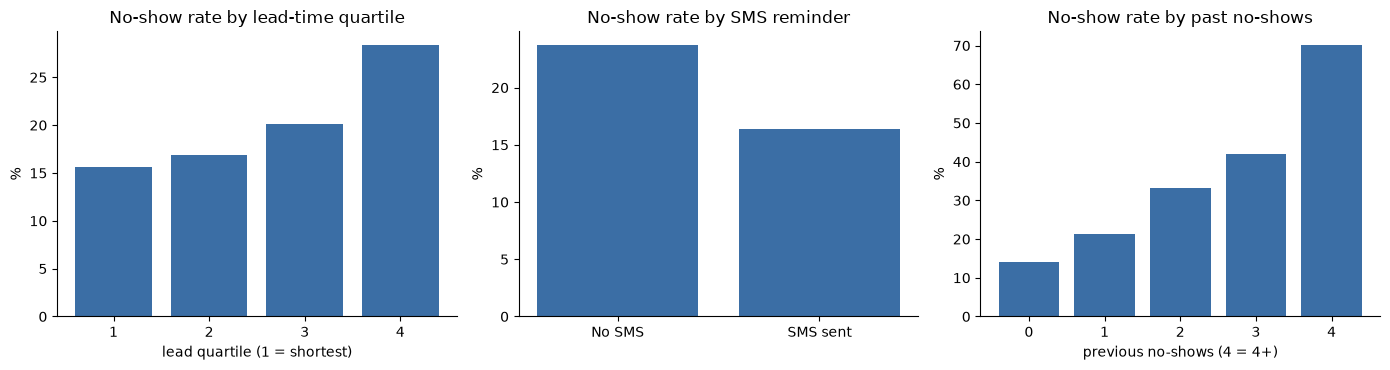

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
by_q = clean.groupby("lead_quartile")["no_show"].mean() * 100
ax[0].bar(by_q.index.astype(str), by_q.values, color="#3b6ea5")
ax[0].set(title="No-show rate by lead-time quartile", xlabel="lead quartile (1 = shortest)", ylabel="%")
by_sms = clean.groupby("sms_received")["no_show"].mean() * 100
ax[1].bar(["No SMS", "SMS sent"], by_sms.values, color="#3b6ea5")
ax[1].set(title="No-show rate by SMS reminder", ylabel="%")
by_prev = clean.assign(prev=clean["previous_no_shows"].clip(upper=4)).groupby("prev")["no_show"].mean() * 100
ax[2].bar(by_prev.index.astype(str), by_prev.values, color="#3b6ea5")
ax[2].set(title="No-show rate by past no-shows", xlabel="previous no-shows (4 = 4+)", ylabel="%")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "figures" / "01_noshow_drivers.png", dpi=130, bbox_inches="tight")